Created 10/15/2025

The goal of this notebook is to test the potential to use lamatrix to do the ACF parabola fitting in a more flexible and robust way.

Currently running this notebook in the ss_local conda environment, but might change to its own env in the future.

I want to reconfigure the flow of SpinSpotter to make it more intuitive to use and debug. The steps go like this:

1. Retrieve a light curve
2. "Clean" the light curve. This could include:
    - Binning (required)
    - Flattening
    - Outliers
    - Masking regions
3. Calculate the ACF
4. Find an "initial guess" for the period. Ideally, this will return several different options. Current method is to use the FFT of the ACF, but make this modular and swappable.
5. Fit parabolas to regions as defined by the PGI. Calcuate descriptive parameters
    - Repeat for each of the pgis
6. Compare descriptive parameters for each pgi and select the preferred period.
7. Return.

Remaining questions:
- How do we want to handle multi sector data? (This again...)
- Do separate runs for a slow/medium/long period search? Perhaps each of them could be binned differently to be more efficient?


Current function flow:
- calc_acf --> produces fits_result
- calc_parabolas
    - prot_prior_func (calc_fft_pgi) --> produces the pgi
        - fft_find_peaks --> calculates the fft and finds the highest peaks
    - curvefit_peak (called iteratively) --> fits parabolas to windows of the acf

This is a mess! Probably want to combine calc_fft_pgi and fft_find_peaks.

My new proposed structure for the pgi finding functions is that it acts all as one step. 
- Inputs: the acf, kwargs
- Outputs: array of pgis (as an index or a value in days?), dictionary reporting on how the pgi-finding went


In [35]:
# import lamatrix
# import SpinSpotter as ss
import sys
sys.path.insert(0,'../spinspotter/')
import function_library as ss


In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 
import importlib

import lightkurve as lk
from statsmodels.tsa.stattools import acf
from scipy.signal import find_peaks, peak_prominences

import lamatrix as la
from lamatrix import Polynomial, Sinusoid, Constant

In [3]:
# get some data
# Option 1: Search and download data using LightKurve.

# this is a short rotator
# TIC 149626644, TESS Sectors 1-8
search_result = lk.search_lightcurve('TIC 149626644', mission='TESS', cadence='short', author='SPOC')
print(search_result)

# Download
# collection = search_result.download_all()
# Plot, to make sure it looks correct
# collection.stitch().plot()
# plt.show()

lcf = search_result[0].download()

SearchResult containing 9 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   149626644      0.0
  1 TESS Sector 02 2018   SPOC     120   149626644      0.0
  2 TESS Sector 03 2018   SPOC     120   149626644      0.0
  3 TESS Sector 05 2018   SPOC     120   149626644      0.0
  4 TESS Sector 06 2018   SPOC     120   149626644      0.0
  5 TESS Sector 08 2019   SPOC     120   149626644      0.0
  6 TESS Sector 09 2019   SPOC     120   149626644      0.0
  7 TESS Sector 12 2019   SPOC     120   149626644      0.0
  8 TESS Sector 13 2019   SPOC     120   149626644      0.0


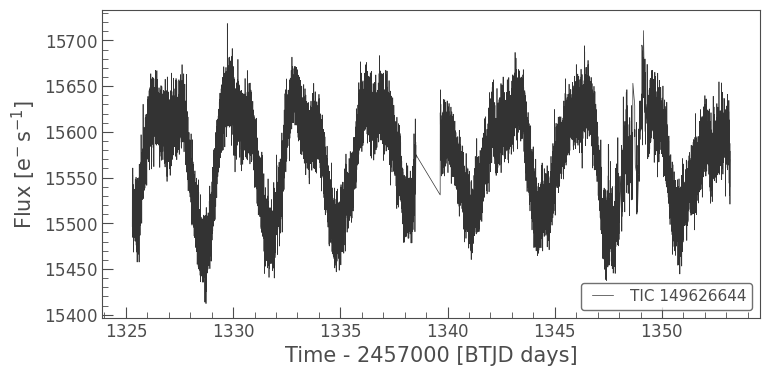

In [4]:
lcf.plot()
plt.show();

In [5]:
lcf.flux.value

MaskedNDArray([15496.387, 15522.626, 15511.492, ..., 15555.807, 15534.416,
               15587.052], dtype='>f4')

In [6]:
# clean
lc_clean = ss.default_cleaning_func(lcf, bs=120)

fr = ss.calc_acf(lc_clean, bs=120)

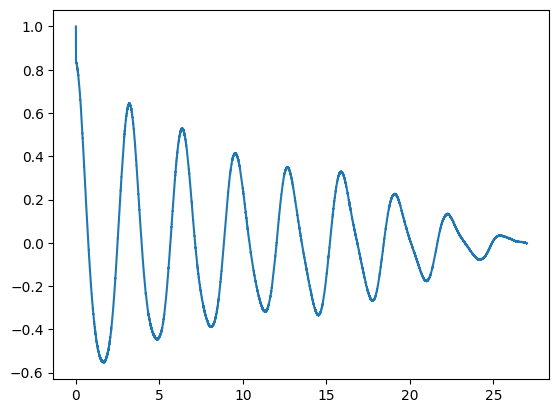

In [7]:
fr.keys()
plt.plot(fr['acf_lags'], fr['acf'])
plt.show()

In [52]:
importlib.reload(ss)

<module 'function_library' from '/Users/raeholcomb/Documents/GitHub/SpinSpotter/dev/../spinspotter/function_library.py'>

In [53]:
pgis, results = ss.calc_fft_pgi(corr)

In [ ]:
# let's improve the fft pgi finding - should be DONE and incorporated into the funciton library now!


from scipy.signal import find_peaks, peak_prominences

corr = fr['acf']
fft_n = 10
day = ss.day
bs = 120
plot = True

# set up results dictionary
results = {}

# Calculate the fft
# changing the coeff increasing the frequency sampling
fft_n = 10
corr_fft = np.real(np.fft.rfft(corr,n=fft_n*len(corr)))
fft_period = np.divide(1., np.fft.rfftfreq(fft_n*len(corr))[1:])

# we're only interested in the positive half of the fft
snip = np.where((fft_period >= 0) & (fft_period <= len(corr)))
fft_period = fft_period[snip]
corr_fft = corr_fft[snip]
fft_period_days = np.divide(fft_period, (day/120))

# find the five tallest peaks, then see how much taller the tallest is
fft_peaks, fft_properties = find_peaks(corr_fft)
peak_heights = corr_fft[fft_peaks]

#initialize the matrix to store the indices of the five peaks
max_peaks = np.zeros(6,dtype=int)

# # if the max peak is too small, fail the test and exit
# # currently set to cut off when the max peak has index less than 5
# if fft_peaks[np.argmax(peak_heights)] < 2 :
#     print( "period is too short")
#     # return -1, {'pgi':-1, 'fft_pgi':-1}

# retrieve the peaks
for i,val in enumerate(max_peaks) :
    index = np.argmax(peak_heights)
    max_peaks[i] = int(fft_peaks[index])
    peak_heights[index] = 0

# # calculate the mean and std of all but the largest peak
# mean_mp = np.mean(corr_fft[max_peaks[1:]])
# std_mp = np.std(corr_fft[max_peaks[1:]])

# # calc how many stds the max peak is from the rest
# pgi_prom = (corr_fft[max_peaks[0]] - mean_mp) / std_mp

print(fft_period_days[max_peaks], peak_heights)

# add to results dictionary
if True:
    # add some results to the results dictionary
    results['fft'] = corr_fft
    results['fft_period'] = fft_period  # period array, in units of index of the acf
    results['fft_period_days'] = np.divide(fft_period, (day/bs))  # period array, in units of index of days
    results['max_peaks_index'] = max_peaks   # indexes of max peaks in the fft
    results['max_peaks_days'] = fft_period_days[max_peaks]   # period of max peaks in the fft
    results['max_peak_heights'] = peak_heights  # heights of max peaks in the fft


# if requested, then plot
if plot :
    plt.figure(figsize=[12,5])
    plt.plot(results['fft_period_days'],corr_fft)
    plt.plot(results['fft_period_days'][max_peaks],corr_fft[max_peaks], marker='x',linestyle='')
    plt.xlabel('Period (d)')
    plt.ylabel('FFT Power')

return results['max_peaks_days'], results

# plot
# plt.figure(figsize=[12,5])
# plt.plot(fft_period_days,corr_fft)
# plt.plot(fft_period_days[max_peaks],corr_fft[max_peaks], marker='x',linestyle='')
# plt.show()

[3.17663399 1.56077392 3.80301252 2.70013889 5.29438998 1.69820056] [ 4.52632844 11.45974465 59.61959888 ...  0.54651141  0.55512322
  0.68569122]


In [120]:
# lets try to get lmfit working with bounds
# fit_params, peak_params, R_adj, fitted_parabola, hwhm = ss.curvefit_peak(ss.parabola,ydata,40,1,plot=False)
# peak_params

output = ss.calc_parabolas(ydata, bs=120)
output.keys()

dict_keys(['smooth', 'fft', 'fft_period', 'pgi', 'a_k', 'b_k', 'c_k', 'Rsq_k', 'hwhm_k', 'fitted_parabola_k', 'P_k', 'A_k', 'B_k', 'P_avg', 'A_avg', 'B_avg', 'R_avg', 'fft_prom', 'P_err', 'half_period', 'half_period_check', 'fail', 'fft_period_days', 'max_peaks', 'peak_heights', 'fft_pgi', 'pgi_prom'])

In [121]:
fft_peaks_i = output['max_peaks']
print(output['fft_period_days'][fft_peaks_i])
print(output['fft'][fft_peaks_i])


[3.17663399 1.56077392 3.80301252 2.70013889 5.29438998 1.69820056]
[3161.36235986  460.02000409  371.53122749  243.21811652  166.20563052
  135.01963717]


In [122]:
[print(i) for i in range(1, 4)]

1
2
3


[None, None, None]

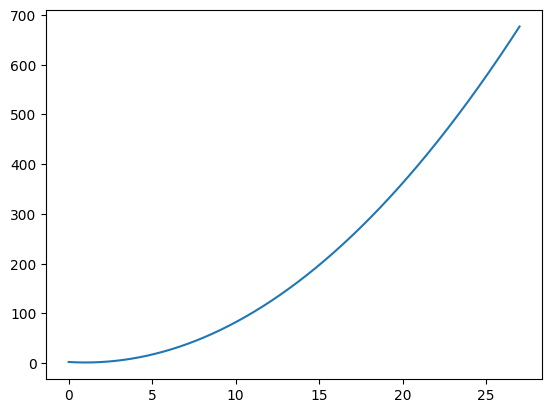

In [123]:
def parabola(x, xshift, yshift):
    return np.square(x-xshift) + yshift

plt.plot(x, parabola(x, 1, 1))
plt.show()

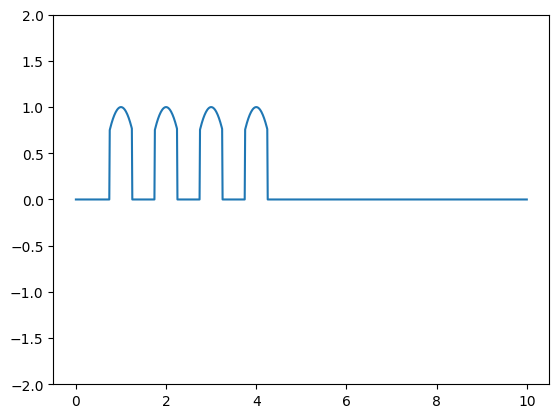

In [64]:
period = 2
x = np.linspace(0,10,1000)


def piecewise_parabola(x, y_pos, x_pos, width):#, num_peaks = 4):
    output = np.zeros_like(x)
    # output = np.array([np.nan] * len(x))
    num_peaks = 4

    for i in range(1, num_peaks+1):
        temp = (x > (i*x_pos - x_pos/4)) & (x < (i*x_pos + x_pos/4))
        output[temp] = width * np.square(x[temp] - i*x_pos) +  y_pos

    return output

plt.plot(x, piecewise_parabola(x, 1, 1, -4))
plt.ylim([-2, 2])
plt.show()

[[Model]]
    Model(piecewise_parabola)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 15
    # data points      = 19441
    # variables        = 3
    chi-square         = 1349.71868
    reduced chi-square = 0.06943712
    Akaike info crit   = -51852.6352
    Bayesian info crit = -51829.0098
    R-squared          = 0.02989871
[[Variables]]
    y_pos: -0.14066355 +/- 0.00736785 (5.24%) (init = 0.5)
    x_pos:  1.99999730 +/- 2.5124e-05 (0.00%) (init = 2)
    width:  0.26540654 +/- 0.06599141 (24.86%) (init = -1)
[[Correlations]] (unreported correlations are < 0.100)
    C(y_pos, width) = -0.7454


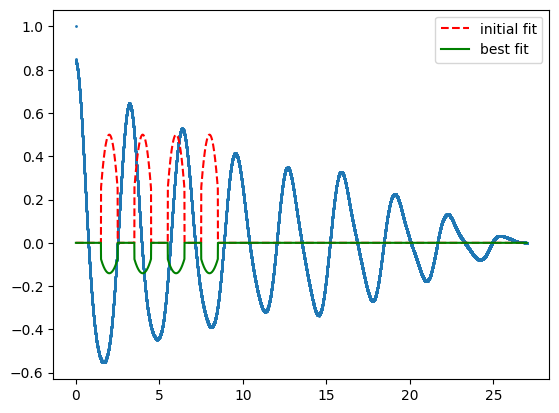

In [66]:
from lmfit import Model

x, y = fr['acf_lags']/1, fr['acf']

# def gaussian(x, amp, cen, wid):
#     """1-d gaussian: gaussian(x, amp, cen, wid)"""
#     return (amp / (sqrt(2*pi) * wid)) * exp(-(x-cen)**2 / (2*wid**2))


gmodel = Model(piecewise_parabola)
result = gmodel.fit(y, x=x, x_pos=2, y_pos=.5, width=-1)

print(result.fit_report())

plt.scatter(x, y, s=1)
plt.plot(x, result.init_fit, '--', c='r', label='initial fit')
plt.plot(x, result.best_fit, '-', c='g', label='best fit')
plt.legend()
plt.show()

x_pos, y_pos, width
[ 1.00006529 -0.0659339   2.49500259]


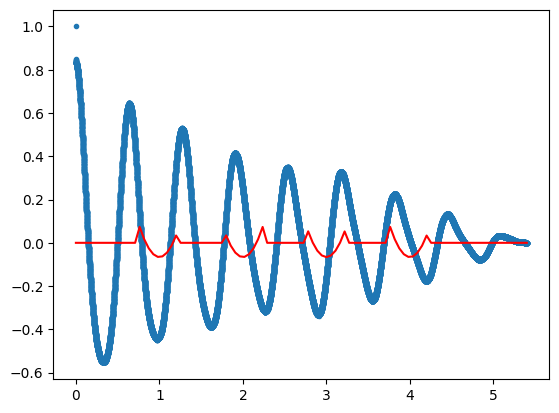

In [49]:
from scipy.optimize import curve_fit
xdata, ydata = fr['acf_lags']/5, fr['acf']
popt, pcov = curve_fit(piecewise_parabola, xdata, ydata)

print("x_pos, y_pos, width")
print(popt)
xfine = np.linspace(xdata.min(), xdata.max(), 100)
plt.plot(xdata, ydata, '.');
plt.plot(xfine, piecewise_parabola(xfine, popt[0], popt[1], popt[2]),'r-')
plt.show()

In [178]:
# set up lamatrix object
from lamatrix import Polynomial, Constant,Gaussian, dGaussian,Distribution, Bounded

x, y = fr['acf_lags'], fr['acf']
# model = (Polynomial('x', order=2) + Constant()) * Sinusoid('x', nterms=25) 
# bm = Bounded(model, (2.5, 4))
# model = Constant() + Polynomial('x', order=2)

# period = 3.2
# model = Gaussian('x', sigma=period/2, mu=period) 
#                 + dGaussian('x', sigma=period/2, mu=period) 
#                 + Constant()
# model.fit(x=x, data=y)



In [168]:
# plt.plot(x[1500:3000],y[1500:3000])
# plt.show()

In [169]:
# [i for i,j in model.posteriors]
# model[1].posteriors

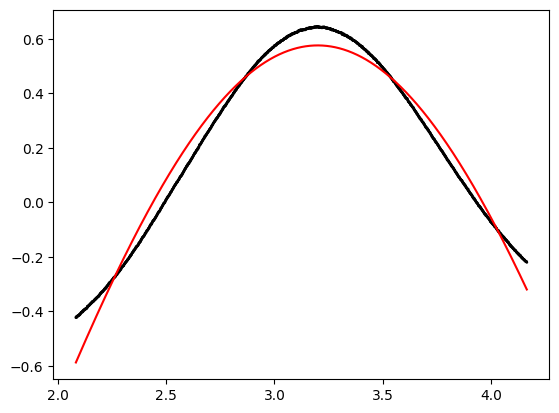

In [170]:
# fig, ax = plt.subplots()
plt.scatter(x, y, ls='', c='k', s=1)
plt.plot(x, model.evaluate(x=x), c='r')
# plt.plot(x, np.asarray([model.sample(x=x) for count in range(100)]).T, c='r', alpha=0.1);
# plt.set(xlabel='$x$', ylabel='$y$', title='Randomly Generated Data');
plt.show()

In [ ]:
# check plot
# plt.plot(lcf.time.value, lcf.flux.value / np.nanmedian(lcf.flux.value) - 1)
# plt.plot(lc_clean.time.value, lc_clean.flux.value)
# plt.show()

# check time plot
# plt.plot(lcf.time.value)
# plt.plot(lc_clean.time.value)
# plt.show()

In [ ]:
# longer period stars
tic = 25063966
# tic = 25064495
# tic = 25064750

search_result = lk.search_lightcurve('TIC ' + str(tic), mission='TESS', author="TGLC")
print(search_result)

# collection = search_result.download_all()

SearchResult containing 10 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   TGLC    1800    25063966      0.0
  1 TESS Sector 02 2018   TGLC    1800    25063966      0.0
  2 TESS Sector 03 2018   TGLC    1800    25063966      0.0
  3 TESS Sector 04 2018   TGLC    1800    25063966      0.0
  4 TESS Sector 06 2018   TGLC    1800    25063966      0.0
  5 TESS Sector 07 2019   TGLC    1800    25063966      0.0
  6 TESS Sector 08 2019   TGLC    1800    25063966      0.0
  7 TESS Sector 09 2019   TGLC    1800    25063966      0.0
  8 TESS Sector 10 2019   TGLC    1800    25063966      0.0
  9 TESS Sector 11 2019   TGLC    1800    25063966      0.0


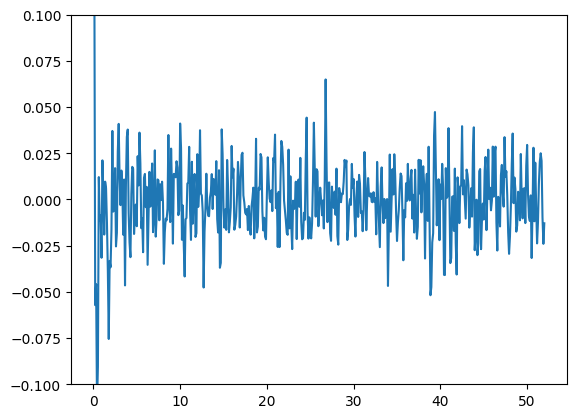

In [ ]:
lcf = collection.stitch().remove_outliers(sigma=4)
# lc.plot()
# plt.show()

# clean
lc_clean = ss.default_cleaning_func(lcf, bs=5*1800)

fr = ss.calc_acf(lc_clean, bs=5*1800)
plt.plot(fr['acf_lags'][:500], fr['acf'][:500])
plt.ylim([-.1, .1])
plt.show()